<a href="https://colab.research.google.com/github/jegillis323/MAT-422/blob/main/MAT422_Section_3_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAT 422 - Section 3.7: Artificial Neural Networks

**Topics:** Mathematical Formulation, Activation Functions, Cost Function, Backpropagation, Backpropagation Algorithm

In [17]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(42)

#3.7.1 Mathematical Formulation

In [18]:
X = np.array([[0,0], [0,1], [1,0], [1,1]], dtype=float)
y = np.array([[0], [1], [1], [0]], dtype=float)

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

W1 = rng.normal(scale=0.5, size=(2, 4))
b1 = np.zeros((1, 4))

W2 = rng.normal(scale=0.5, size=(4, 1))
b2 = np.zeros((1, 1))

def forward(X):
    z1 = X @ W1 + b1
    a1 = np.tanh(z1)
    z2 = a1 @ W2 + b2
    a2 = sigmoid(z2)
    return z1, a1, z2, a2

_, hidden, _, output = forward(X)
print("Hidden layer values:")
print(hidden)
print("Initial predicted probabilities:")
print(output)

Hidden layer values:
[[ 0.          0.          0.          0.        ]
 [-0.75111895 -0.57240312  0.06383329 -0.15681654]
 [ 0.15119048 -0.47769388  0.35855401  0.43842743]
 [-0.67678562 -0.82461866  0.41293615  0.30240182]]
Initial predicted probabilities:
[[0.5       ]
 [0.55417016]
 [0.62963128]
 [0.65849032]]


My Explanation: This is a small neural network that takes two inputs, transforms them with four hidden neurons, which all have different weights and biases, along with an activation function that all change the final output. These parameters produce a singular output neuron, which is the initial predicted probabilities.

#3.7.2 Activation Function

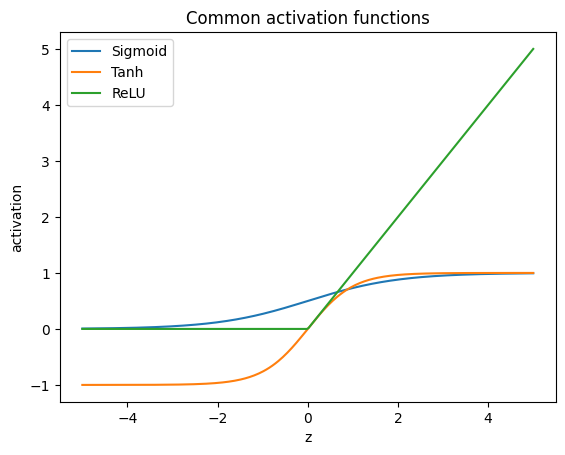

In [19]:
def relu(z):
    return np.maximum(0, z)

z = np.linspace(-5, 5, 300)
plt.plot(z, sigmoid(z), label="Sigmoid")
plt.plot(z, np.tanh(z), label="Tanh")
plt.plot(z, relu(z), label="ReLU")
plt.xlabel("z")
plt.ylabel("activation")
plt.title("Common activation functions")
plt.legend()
plt.show()

My Explanation: This shows a graph of three main activation functions that are used to transform the weighted inputs on the neurons and allow for nonlinearity. Sigmoid maps values into either 0 or 1, which can be useful for binary output probability. Tanh maps values into -1 and 1, which is what the hidden neurons used for the earlier neural network. ReLU returns 0 for negative inputs and the input itself for positive inputs.

#3.7.3 Cost Function

In [20]:
def binary_cross_entropy(y_true, y_prob):
    eps = 1e-9
    return -np.mean(y_true*np.log(y_prob + eps) + (1-y_true)*np.log(1-y_prob + eps))

initial_loss = binary_cross_entropy(y, output)

print("Target values:", y.ravel())
print("Initial probabilities:", output.ravel())
print("Initial binary cross-entropy:", initial_loss)

final_loss = binary_cross_entropy(y, final_output)

print("Final binary cross-entropy:", final_loss)

Target values: [0. 1. 1. 0.]
Initial probabilities: [0.5        0.55417016 0.62963128 0.65849032]
Initial binary cross-entropy: 0.7051077051423861
Final binary cross-entropy: 0.00047319565263840896


My Explanation: The cost function measures how differently a neural network's prediction is from the correct target values. Binary cross entropy is used here because the networks performs a binary classification with targets 0 and 1. A larger loss indicates that there were poorer predicitions, while a smaller loss indicates that the predictions were closer to the correct values. Training is then used to minimize the loss.

#3.7.4 Backpropagation

In [21]:
z1, a1, z2, a2 = forward(X)
dz2 = (a2 - y) / len(X)
dW2 = a1.T @ dz2
db2 = dz2.sum(axis=0, keepdims=True)
da1 = dz2 @ W2.T
dz1 = da1 * (1 - np.tanh(z1)**2)
dW1 = X.T @ dz1
db1 = dz1.sum(axis=0, keepdims=True)

print("dW2 shape:", dW2.shape)
print("db2 shape:", db2.shape)
print("dW1 shape:", dW1.shape)
print("db1 shape:", db1.shape)
print("Backpropagation sends the output error backward through W2 and the tanh derivative.")
print("Output Error:")
print((a2 - y).ravel())


dW2 shape: (4, 1)
db2 shape: (1, 1)
dW1 shape: (2, 4)
db1 shape: (1, 4)
Backpropagation sends the output error backward through W2 and the tanh derivative.
Output Error:
[ 0.5        -0.44582984 -0.37036872  0.65849032]


My Explanation: Backpropagation determines how the network's weights and biases contribute to the prediction error. It uses the error from the output layer and works backwords through the network to calculate the gradient for the paramet. The gradient indicates how each weight or bias should be changed to reduce the cost function, thus the error.

#3.7.5 Backpropagation Algorithm

Target values: [0. 1. 1. 0.]
Final probabilities: [5.93251952e-04 9.97864237e-01 9.98094014e-01 2.67392501e-03]
Final predictions: [0 1 1 0]
Final loss: 0.0018291954016383012


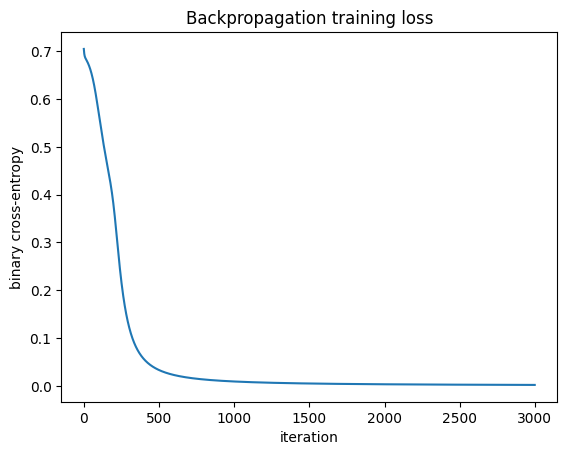

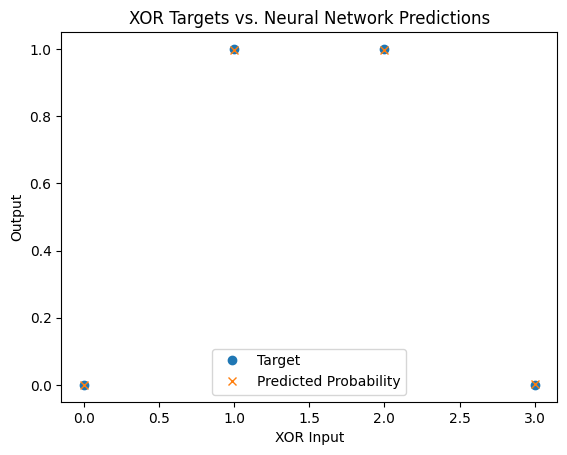

In [22]:
learning_rate = 0.3
epochs = 3000
losses = []
for step in range(epochs):
    z1 = X @ W1 + b1
    a1 = np.tanh(z1)
    z2 = a1 @ W2 + b2
    a2 = sigmoid(z2)
    losses.append(binary_cross_entropy(y, a2))

    dz2 = (a2 - y) / len(X)
    dW2 = a1.T @ dz2
    db2 = dz2.sum(axis=0, keepdims=True)
    da1 = dz2 @ W2.T
    dz1 = da1 * (1 - np.tanh(z1)**2)
    dW1 = X.T @ dz1
    db1 = dz1.sum(axis=0, keepdims=True)

    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2
    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1

_, _, _, final_output = forward(X)

final_predictions = (final_output > 0.5).astype(int)

print("Target values:", y.ravel())
print("Final probabilities:", final_output.ravel())
print("Final predictions:", final_predictions.ravel())
print("Final loss:", binary_cross_entropy(y, final_output))

plt.plot(losses)
plt.xlabel("iteration")
plt.ylabel("binary cross-entropy")
plt.title("Backpropagation training loss")
plt.show()

plt.plot(y.ravel(), "o", label="Target")
plt.plot(final_output.ravel(), "x", label="Predicted Probability")
plt.xlabel("XOR Input")
plt.ylabel("Output")
plt.title("XOR Targets vs. Neural Network Predictions")
plt.legend()
plt.show()

My Explanation: The backpropagation algorithm repeatedly combines forward propagation, calculation of the loss, backpropagation, and gradient descent to minimize the loss. The network makes predictions, calculates the error, determines the gradients through backpropagation, and updates the weights and biases in the direction that reduces the loss. Repeating this many times will allow the network to gradually learn the pattern, which can be seen as the loss decreases and the final predicted probabilites become much closer to the target values than the initial prediction.